# Air Quality Index (AQI) in India, 2022-2025: Data Transformation, Null Handling, Insights and Visualization

**Dataset:** Daily AQI by area and state across India (CPCB data), file `aqi.csv`.

**Columns:** `date`, `state`, `area`, `number_of_monitoring_stations`, `prominent_pollutants`, `aqi_value`, `air_quality_status`, `note`.
(A constant text column `unit` was removed from the file before upload to keep it under GitHub's 25 MB limit.)

## 1. Dataset Selection and Reading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("aqi.csv")
df.head()

,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,NaN


## 2. Data Understanding

In [3]:
print("Rows and columns:", df.shape)
print("States:", df['state'].nunique())
print("Areas:", df['area'].nunique())

Rows and columns: (235785, 8)
States: 32
Areas: 291


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235785 entries, 0 to 235784
Data columns (total 8 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   date                           235785 non-null  str    
 1   state                          235785 non-null  str    
 2   area                           235785 non-null  str    
 3   number_of_monitoring_stations  235785 non-null  int64  
 4   prominent_pollutants           235785 non-null  str    
 5   aqi_value                      235785 non-null  int64  
 6   air_quality_status             235785 non-null  str    
 7   note                           0 non-null       float64
dtypes: float64(1), int64(2), str(5)
memory usage: 14.4 MB


In [5]:
df.describe()

,number_of_monitoring_stations,aqi_value,note
count,235785.000000,235785.000000,0.0
mean,1.870653,111.127294,NaN
std,3.071575,71.447353,NaN
min,1.000000,3.000000,NaN
25%,1.000000,59.000000,NaN
50%,1.000000,92.000000,NaN
75%,1.000000,142.000000,NaN
max,40.000000,500.000000,NaN


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print()
print(df['air_quality_status'].value_counts())

Duplicate rows: 0

air_quality_status
Satisfactory    88897
Moderate        77537
Good            41971
Poor            21154
Very Poor        5671
Severe            555
Name: count, dtype: int64


## 3. Identifying Null Values

In [7]:
null_pct = (df.isnull().sum() / len(df) * 100).round(2)
print(null_pct)

date                               0.0
state                              0.0
area                               0.0
number_of_monitoring_stations      0.0
prominent_pollutants               0.0
aqi_value                          0.0
air_quality_status                 0.0
note                             100.0
dtype: float64


Only the `note` column has nulls (it is completely empty). The numeric columns (`aqi_value`, `number_of_monitoring_stations`) have no explicit nulls.

However, not every area reports every day, so there are **missing area-days** hidden in the data. These become visible nulls when the data is reshaped into a date x location table (Section 5).

## 4. Data Transformation

- Drop `unit` (constant text, if present) and `note` (100% empty)
- Convert `date` from text to datetime
- Convert `air_quality_status` to an ordered category (Good < Satisfactory < ... < Severe)
- Add `Year`, `Month`, `Season` and a `location` column (`area, state`, because some area names repeat across states)

In [8]:
df = df.drop(columns=['unit', 'note'], errors='ignore')

df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')

status_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
df['air_quality_status'] = pd.Categorical(df['air_quality_status'], categories=status_order, ordered=True)

df['Year'] = df['date'].dt.year
df['Month'] = df['date'].dt.month

def get_season(month):
    if month in (12, 1, 2):
        return 'Winter'
    elif month in (3, 4, 5):
        return 'Summer'
    elif month in (6, 7, 8, 9):
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

df['Season'] = df['Month'].apply(get_season)
df['location'] = df['area'] + ', ' + df['state']

print("Date range:", df['date'].min().date(), "to", df['date'].max().date())
print(df.dtypes)

Date range: 2022-04-01 to 2025-04-30
date                             datetime64[us]
state                                       str
area                                        str
number_of_monitoring_stations             int64
prominent_pollutants                        str
aqi_value                                 int64
air_quality_status                     category
Year                                      int32
Month                                     int32
Season                                      str
location                                    str
dtype: object


## 5. Handling Null Values (Mean Imputation)

Reshaping the data into a **date x location** table shows which area-days have no reading. Those gaps are filled with the **mean AQI of the same location**.

Locations that reported on fewer than 50% of days are left out of this table, because they have too little data to estimate a reliable mean.

In [9]:
n_dates = df['date'].nunique()
coverage = df.groupby('location')['date'].nunique() / n_dates

print("Total locations:", len(coverage))
print("Locations reporting on fewer than 50% of days:", (coverage < 0.5).sum())

keep = coverage[coverage >= 0.5].index
aqi_grid = df[df['location'].isin(keep)].pivot_table(index='date', columns='location', values='aqi_value')

print("Table shape (dates x locations):", aqi_grid.shape)

Total locations: 292
Locations reporting on fewer than 50% of days: 49


Table shape (dates x locations): (1125, 243)


In [10]:
missing_before = aqi_grid.isnull().sum().sum()
print(f"Missing area-days before imputation: {missing_before:,} of {aqi_grid.size:,} ({missing_before / aqi_grid.size * 100:.1f}%)")

# mean imputation: each location's gaps are filled with that location's own mean AQI
aqi_filled = aqi_grid.fillna(aqi_grid.mean())

print("Missing area-days after imputation:", aqi_filled.isnull().sum().sum())

Missing area-days before imputation: 54,295 of 273,375 (19.9%)
Missing area-days after imputation: 0


## 6. Insight Generation

In [11]:
# Insight 1: most and least polluted states (average AQI)
state_aqi = df.groupby('state')['aqi_value'].mean().sort_values(ascending=False)
print("Top 10 most polluted states:")
print(state_aqi.head(10).round(1))
print()
print("5 cleanest states:")
print(state_aqi.tail(5).round(1))

Top 10 most polluted states:


state
Delhi               206.4
Jharkhand           164.9
Himachal Pradesh    160.3
Bihar               157.2
Chandigarh          141.6
Haryana             140.9
Rajasthan           128.0
Tripura             126.7
Uttar Pradesh       126.4
Odisha              124.9
Name: aqi_value, dtype: float64

5 cleanest states:
state
Andaman and Nicobar Islands    57.7
Puducherry                     56.5
Arunachal Pradesh              54.5
Sikkim                         53.7
Mizoram                        47.2
Name: aqi_value, dtype: float64


In [12]:
# Insight 2: most polluted locations (only locations with enough data)
loc_aqi = df[df['location'].isin(keep)].groupby('location')['aqi_value'].mean().sort_values(ascending=False)
print("Top 10 most polluted locations:")
print(loc_aqi.head(10).round(1))

Top 10 most polluted locations:
location
Byrnihat, Assam                 240.0
Begusarai, Bihar                206.7
Delhi, Delhi                    206.4
Greater Noida, Uttar Pradesh    201.6
Sri Ganganagar, Rajasthan       197.9
Gurugram, Haryana               190.8
Dharuhera, Haryana              185.7
NOIDA, Uttar Pradesh            184.0
Ghaziabad, Uttar Pradesh        183.0
Faridabad, Haryana              181.9
Name: aqi_value, dtype: float64


In [13]:
# Insight 3: national monthly trend (average over all kept locations, after imputation)
national_daily = aqi_filled.mean(axis=1)
monthly = national_daily.groupby(national_daily.index.to_period('M')).mean()
monthly.index = monthly.index.to_timestamp()

print("Worst 5 months:")
print(monthly.sort_values(ascending=False).head(5).round(1))
print()
print("Best 5 months:")
print(monthly.sort_values().head(5).round(1))

Worst 5 months:
date
2023-11-01    164.9
2023-01-01    156.1
2022-12-01    155.5
2024-11-01    154.4
2024-01-01    153.9
dtype: float64

Best 5 months:
date
2024-08-01    63.1
2024-09-01    69.4
2024-07-01    69.7
2023-07-01    71.7
2023-09-01    76.1
dtype: float64


In [14]:
# Insight 4: seasonal pattern
season_order = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
season_aqi = national_daily.groupby(national_daily.index.month.map(get_season)).mean().reindex(season_order)
print(season_aqi.round(1))

date
Winter          139.0
Summer          112.1
Monsoon          81.0
Post-Monsoon    132.3
dtype: float64


In [15]:
# Insight 5: major cities, monthly average AQI
metros = ['Delhi, Delhi', 'Mumbai, Maharashtra', 'Bengaluru, Karnataka', 'Chennai, Tamil Nadu', 'Kolkata, West Bengal']
metros = [m for m in metros if m in aqi_filled.columns]

metro_monthly = aqi_filled[metros].groupby(aqi_filled.index.to_period('M')).mean()
metro_monthly.index = metro_monthly.index.to_timestamp()

print("Average AQI of major cities:")
print(aqi_filled[metros].mean().round(1))

Average AQI of major cities:
location
Delhi, Delhi            206.4
Mumbai, Maharashtra     105.9
Bengaluru, Karnataka     74.9
Chennai, Tamil Nadu      74.0
Kolkata, West Bengal    102.0
dtype: float64


In [16]:
# Insight 6: which pollutant is most often the prominent one
pollutant_counts = (
    df['prominent_pollutants'].str.split(',').explode().str.strip().value_counts()
)
print(pollutant_counts)

prominent_pollutants
PM10     135806
PM2.5     78030
O3        24951
CO        18148
NO2        6025
SO2        5284
NH3          83
SO3          40
Name: count, dtype: int64


In [17]:
# Insight 7: share of days in each AQI category
status_counts = df['air_quality_status'].value_counts().reindex(status_order)
print((status_counts / status_counts.sum() * 100).round(1))

air_quality_status
Good            17.8
Satisfactory    37.7
Moderate        32.9
Poor             9.0
Very Poor        2.4
Severe           0.2
Name: count, dtype: float64


## 7. Data Visualization

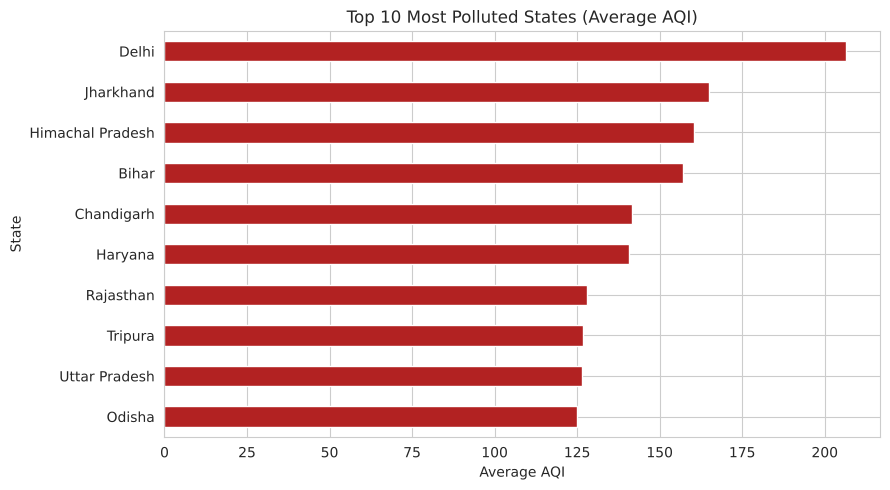

In [18]:
plt.figure(figsize=(9, 5))
state_aqi.head(10).sort_values().plot(kind='barh', color='firebrick')
plt.title('Top 10 Most Polluted States (Average AQI)')
plt.xlabel('Average AQI')
plt.ylabel('State')
plt.tight_layout()
plt.show()

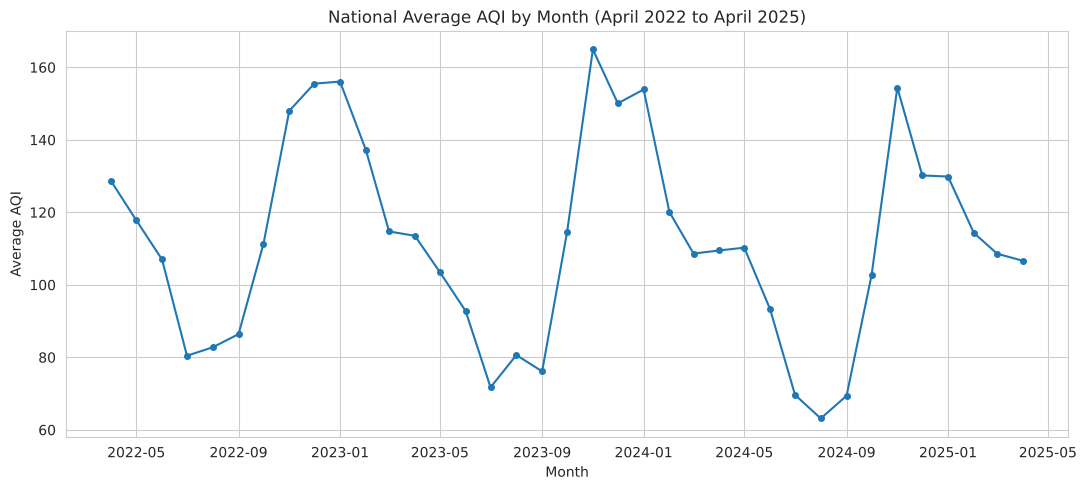

In [19]:
plt.figure(figsize=(11, 5))
plt.plot(monthly.index, monthly.values, marker='o', markersize=4)
plt.title('National Average AQI by Month (April 2022 to April 2025)')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.tight_layout()
plt.show()

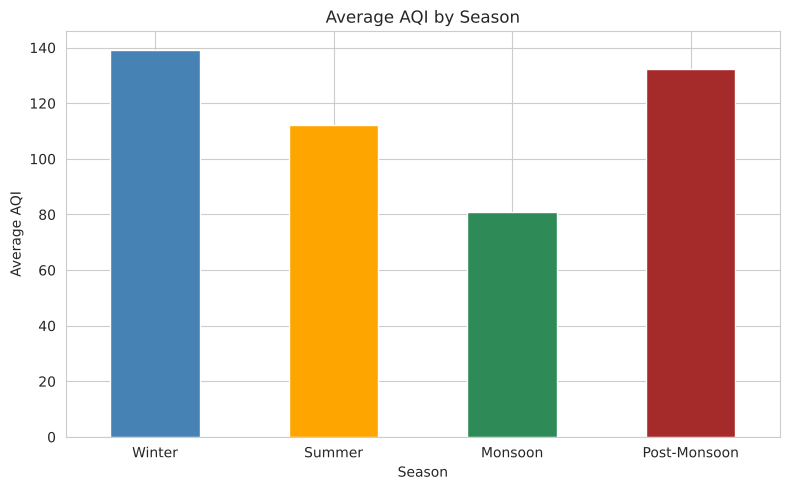

In [20]:
plt.figure(figsize=(8, 5))
season_aqi.plot(kind='bar', color=['steelblue', 'orange', 'seagreen', 'brown'])
plt.title('Average AQI by Season')
plt.xlabel('Season')
plt.ylabel('Average AQI')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

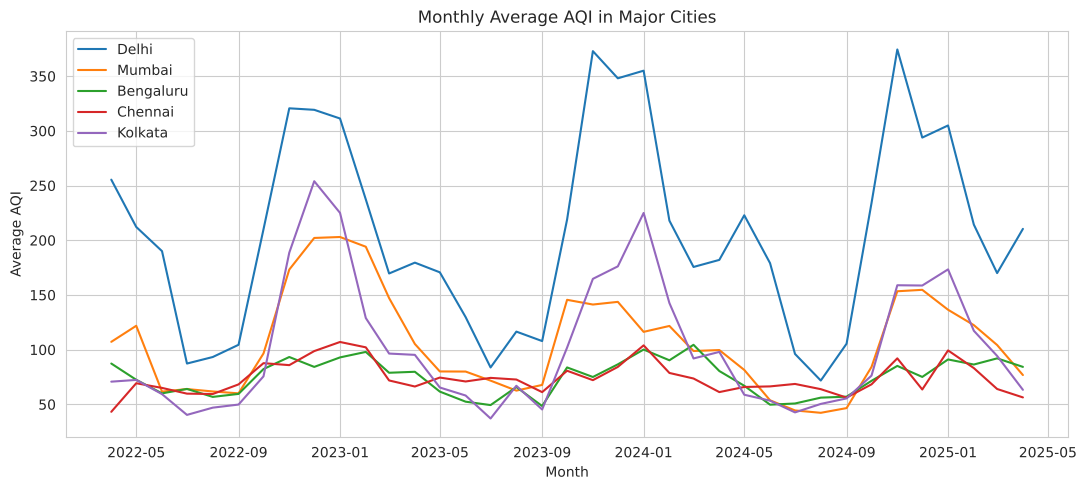

In [21]:
plt.figure(figsize=(11, 5))
for city in metro_monthly.columns:
    plt.plot(metro_monthly.index, metro_monthly[city], label=city.split(',')[0])
plt.title('Monthly Average AQI in Major Cities')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.legend()
plt.tight_layout()
plt.show()

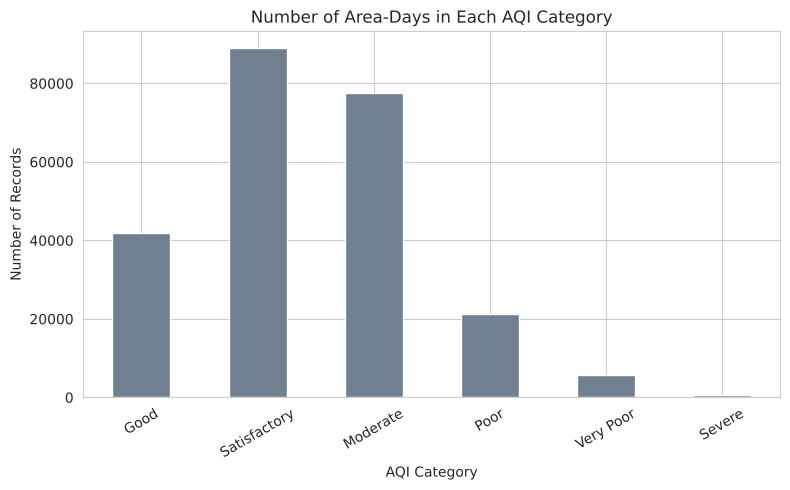

In [22]:
plt.figure(figsize=(8, 5))
status_counts.plot(kind='bar', color='slategray')
plt.title('Number of Area-Days in Each AQI Category')
plt.xlabel('AQI Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

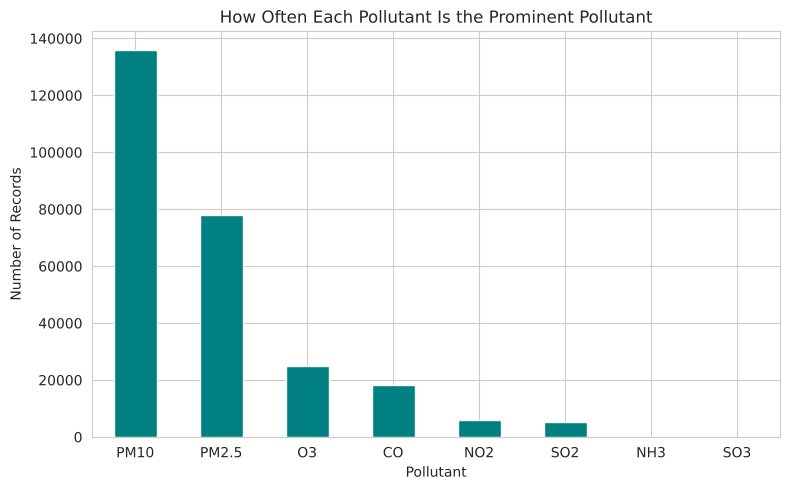

In [23]:
plt.figure(figsize=(8, 5))
pollutant_counts.plot(kind='bar', color='teal')
plt.title('How Often Each Pollutant Is the Prominent Pollutant')
plt.xlabel('Pollutant')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

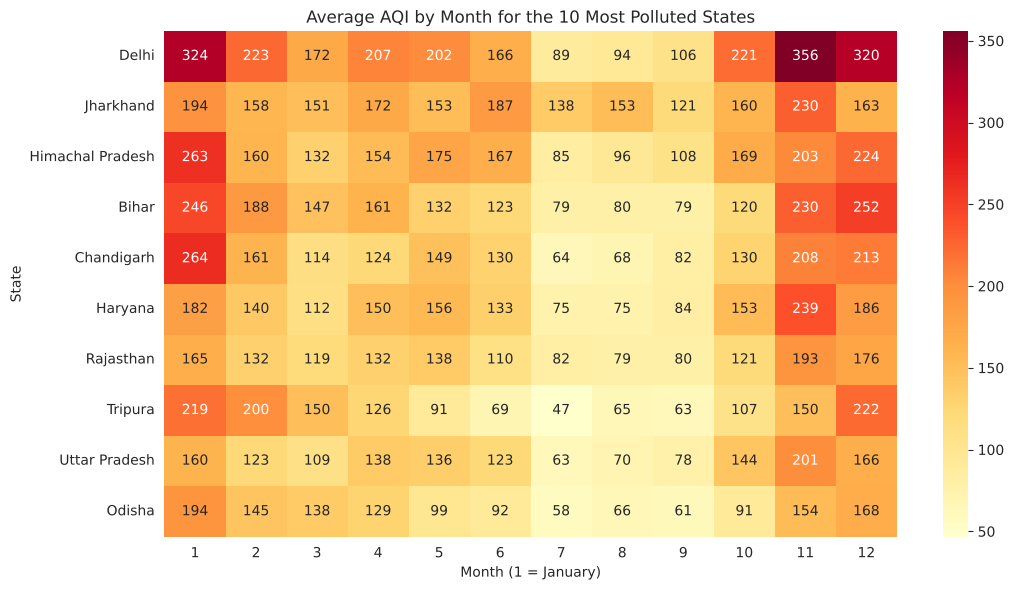

In [24]:
top_states = state_aqi.head(10).index
heat = df[df['state'].isin(top_states)].pivot_table(index='state', columns='Month', values='aqi_value', aggfunc='mean')
heat = heat.loc[top_states]

plt.figure(figsize=(11, 6))
sns.heatmap(heat, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Average AQI by Month for the 10 Most Polluted States')
plt.xlabel('Month (1 = January)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

## 8. Conclusion

*Write this section in your own words using the numbers from your outputs above.*

- Which states and locations are the most and least polluted?
- Which months and seasons have the worst air quality?
- How do the major cities compare?
- Which pollutant is most often prominent?
- What cleaning was done (columns dropped, data types changed, how missing area-days were imputed)?